# NB03 — Stage 1 Baseline (OralXray, No Gaze)

**Phase 1 of v23 pipeline:** train Swin-T + LoRA on **OralXray** only (`λ=0`, no gaze loss).

| Output | Description |
|---|---|
| `checkpoints/stage1_best.pth` | Best OralXray-trained weights (used by NB04) |
| `results/stage1_metrics.json` | OralXray test (primary) + Tufts test (zero-shot) |
| `results/stage1_oralxray_per_image_predictions.csv` | Per-image OralXray test preds |

**Not Tufts training** — Tufts is evaluated only as zero-shot transfer in the final eval cell.


In [ ]:
import sys, os
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    pass

Mounted at /content/drive


In [ ]:
# === Colab setup (plan §1.2) ===
try:
    from google.colab import drive
except ImportError:
    pass

import os, sys, json, shutil, glob, zipfile, inspect

CODE_DIR = '/content/dental_code'
LOCAL_DATA = '/content/dental_data'
LOCAL_ZIP_CACHE = '/content/dental_zip_cache'
os.makedirs(CODE_DIR, exist_ok=True)


def find_project_root():
    candidates = []
    shortcut_base = '/content/drive/.shortcut-targets-by-id'
    if os.path.isdir(shortcut_base):
        for entry in os.listdir(shortcut_base):
            candidates.append(os.path.join(shortcut_base, entry, 'DENTAL'))
    candidates += [
        '/content/drive/MyDrive/DENTAL',
        os.path.abspath('..') if os.path.basename(os.getcwd()) == 'Notebooks' else None,
        os.getcwd(),
    ]
    for p in candidates:
        if p and os.path.isfile(os.path.join(p, 'config.json')):
            return os.path.abspath(p)
    raise FileNotFoundError(
        'Cannot locate DENTAL project (config.json). Mount Drive and open from Notebooks/.'
    )


def upgrade_dental_dataset_hybrid(code_dir, project_root):
    """Patch stale Drive copy so DentalDataset accepts image_root."""
    path = os.path.join(code_dir, 'dental_dataset.py')
    with open(path, 'r', encoding='utf-8') as f:
        text = f.read()
    if 'image_root' in text:
        return False
    text = text.replace(
        'def __init__(self, csv_path, project_root, augment=False):',
        'def __init__(self, csv_path, project_root, augment=False, image_root=None):',
    )
    text = text.replace(
        '        self.root         = project_root\n        self.augment      = augment',
        '        self.root         = project_root\n        self.image_root   = image_root or project_root\n        self.augment      = augment',
    )
    text = text.replace(
        '        full = path if os.path.isabs(path) else os.path.join(self.root, path)\n        img = Image.open(full).convert',
        '        full = path if os.path.isabs(path) else os.path.join(self.image_root, path)\n        img = Image.open(full).convert',
        1,
    )
    text = text.replace(
        'def build_dataloaders(CONFIG, project_root, batch_size=None, fold=None, smoke_test=False):',
        'def build_dataloaders(CONFIG, project_root, batch_size=None, fold=None, smoke_test=False, image_root=None):',
    )
    text = text.replace(
        "    bs = batch_size or CONFIG['chosen_batch_size']\n    train_df = pd.read_csv",
        "    bs = batch_size or CONFIG['chosen_batch_size']\n    img_root = image_root or project_root\n    train_df = pd.read_csv",
    )
    for old, new in [
        ('DentalDataset(tr_csv, project_root, augment=True)', 'DentalDataset(tr_csv, project_root, augment=True, image_root=img_root)'),
        ('DentalDataset(vl_csv, project_root, augment=False)', 'DentalDataset(vl_csv, project_root, augment=False, image_root=img_root)'),
        ('project_root, augment=True)', 'project_root, augment=True, image_root=img_root)'),
        ('project_root, augment=False)', 'project_root, augment=False, image_root=img_root)'),
    ]:
        text = text.replace(old, new)
    with open(path, 'w', encoding='utf-8') as f:
        f.write(text)
    shutil.copy2(path, os.path.join(project_root, 'dental_dataset.py'))
    if 'dental_dataset' in sys.modules:
        del sys.modules['dental_dataset']
    print('Upgraded dental_dataset.py for hybrid I/O (image_root)')
    return True


def cache_project_modules(project_root, code_dir=CODE_DIR):
    os.makedirs(code_dir, exist_ok=True)
    for fname in ('dental_dataset.py', 'core_modules.py'):
        src = os.path.join(project_root, fname)
        dst = os.path.join(code_dir, fname)
        if not os.path.isfile(src):
            raise FileNotFoundError(f'{src} missing — run NB01_model.ipynb first.')
        shutil.copy2(src, dst)
    if code_dir not in sys.path:
        sys.path.insert(0, code_dir)
    upgrade_dental_dataset_hybrid(code_dir, project_root)
    return code_dir


PROJECT = find_project_root()
NOTEBOOKS_DIR = os.path.join(PROJECT, 'Notebooks')
cache_project_modules(PROJECT)
for p in (PROJECT, NOTEBOOKS_DIR):
    if p not in sys.path:
        sys.path.insert(0, p)
os.chdir(PROJECT)

with open('config.json', 'r') as f:
    CONFIG = json.load(f)

print('Working directory:', os.getcwd())
print('Code modules cached to:', CODE_DIR)
print('Resolution:', CONFIG['chosen_resolution'], '| batch:', CONFIG['chosen_batch_size'],
      '| grad_accum:', CONFIG['chosen_grad_accum'])
print('Stage-1 epochs:', CONFIG['num_epochs_stage1'], '| default gaze_lambda:', CONFIG['gaze_lambda'])


Working directory: /content/drive/MyDrive/DENTAL
Code modules cached to: /content/dental_code
Resolution: 224 | batch: 64 | grad_accum: 2
Stage-1 epochs: 40 | default gaze_lambda: 0.1


In [ ]:
!pip install --upgrade torchao
!pip install -q torch torchvision transformers peft scikit-learn pandas numpy tqdm pillow opencv-python matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 51.7 MB/s eta 0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


## 1 — Runtime setup & mode selection

`ON_GPU` drives the whole notebook. CPU = code-validation dry run only; GPU = real
Stage-2 training. Same flags as NB02 (`SMOKE_TEST`, `NUM_WORKERS`).

In [ ]:
import random
import numpy as np
import torch
torch.backends.cudnn.deterministic = True
import shutil
from tqdm.auto import tqdm
# import cv2
import pandas as pd
# from PIL import Image
from torch.utils.data import DataLoader

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    import numpy as np
    import random
    np.random.seed(worker_seed)
    random.seed(worker_seed)


SEED = int(CONFIG.get('random_seed', 42))
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ON_GPU = torch.cuda.is_available()

# Set True ONLY for a quick end-to-end smoke test (1 epoch, tiny subset). Does NOT
# flip the CPU/GPU contract — it just shrinks the GPU run.
SMOKE_TEST = False
RESUME_TRAINING = True  # False = ignore stage1_last_fold*.pth and retrain folds
NUM_WORKERS = 2  # Eliminated child process AssertionError
torch.backends.cudnn.benchmark = True

os.makedirs('checkpoints', exist_ok=True)
os.makedirs('results', exist_ok=True)

# Status flags — always defined so later cells never NameError on partial/CPU runs
CODE_CHECK_PASSED = False
REAL_TRAIN_DONE = False
NUM_FOLDS = 1  # 1 single run for stratified 80/10/10 split (no GPU waste in pre-training)
best_dice = -1.0
best_fold = None
epoch = -1
final_metrics = None
all_fold_results = []
agg_metrics = {}

if ON_GPU:
    print(f'>>> GPU detected ({torch.cuda.get_device_name(0)}) — REAL Stage-2 training will run.')
else:
    print('>>> NO GPU detected — running CODE-VALIDATION DRY RUN only (no training).')
print('SMOKE_TEST:', SMOKE_TEST)

>>> GPU detected (Tesla T4) — REAL Stage-2 training will run.
SMOKE_TEST: False


In [ ]:
# === Local images from Drive zip archives (everything else stays on Drive) ===
# Contract:
#   Drive (PROJECT): splits/, gaze_maps_48x48/, checkpoints/, results/, config.json
#   Local (LOCAL_DATA): data/ only (unzipped from PROJECT/Data zip/*.zip)

DATA_ZIP_DIR = os.path.join(PROJECT, 'Data zip')
DATA_MARKER = os.path.join(LOCAL_DATA, 'data', 'tdd', 'Expert', 'expert.json')


def ensure_drive_metadata():
    required = [
        'splits/train_split.csv',
        'splits/val_split.csv',
        'gaze_maps_48x48',
        'dental_dataset.py',
        'core_modules.py',
    ]
    missing = [p for p in required if not os.path.exists(os.path.join(PROJECT, p))]
    if missing:
        raise FileNotFoundError(
            'Missing on Drive (run NB00/NB01 first): ' + ', '.join(missing)
        )


def ensure_local_images_from_zip():
    """Copy zip shards from Drive to local cache, unzip into LOCAL_DATA/data/."""
    os.makedirs(LOCAL_DATA, exist_ok=True)
    os.makedirs(LOCAL_ZIP_CACHE, exist_ok=True)
    ensure_drive_metadata()

    if os.path.exists(DATA_MARKER):
        print(f'Local images already present: {os.path.join(LOCAL_DATA, "data")}')
        print(f'Metadata on Drive: {PROJECT}')
        return

    if not os.path.isdir(DATA_ZIP_DIR):
        raise FileNotFoundError(f'Missing zip folder: {DATA_ZIP_DIR}')

    zip_on_drive = sorted(glob.glob(os.path.join(DATA_ZIP_DIR, '*.zip')))
    if not zip_on_drive:
        raise FileNotFoundError(f'No .zip files in {DATA_ZIP_DIR}')

    for src_zip in zip_on_drive:
        name = os.path.basename(src_zip)
        dst_zip = os.path.join(LOCAL_ZIP_CACHE, name)
        if (not os.path.exists(dst_zip)) or os.path.getsize(dst_zip) != os.path.getsize(src_zip):
            print(f'Copying zip Drive -> local cache: {name}')
            shutil.copy2(src_zip, dst_zip)
        else:
            print(f'Zip cache hit: {name}')
        print(f'Unzipping {name} -> {LOCAL_DATA} ...')
        with zipfile.ZipFile(dst_zip, 'r') as zf:
            zf.extractall(LOCAL_DATA)

    if not os.path.exists(DATA_MARKER):
        raise FileNotFoundError(
            'Unzip finished but data/tdd/Expert/expert.json missing. '
            'Zip archives must contain a top-level data/ folder.'
        )
    print(f'Local images ready: {os.path.join(LOCAL_DATA, "data")}')
    print(f'Splits + gaze + artifacts on Drive: {PROJECT}')


ensure_local_images_from_zip()


Copying zip Drive -> local cache: data-20260715T052740Z-1-001.zip
Unzipping data-20260715T052740Z-1-001.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-002.zip
Unzipping data-20260715T052740Z-1-002.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-003.zip
Unzipping data-20260715T052740Z-1-003.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-004.zip
Unzipping data-20260715T052740Z-1-004.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-005.zip
Unzipping data-20260715T052740Z-1-005.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-006.zip
Unzipping data-20260715T052740Z-1-006.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T052740Z-1-007.zip
Unzipping data-20260715T052740Z-1-007.zip -> /content/dental_data ...
Copying zip Drive -> local cache: data-20260715T

In [ ]:
# === Validate hybrid I/O (loop until 3 consecutive clean passes) ===
import importlib


def validate_hybrid_io():
    errors = []
    ensure_drive_metadata()
    if not os.path.exists(DATA_MARKER):
        errors.append('local data/ images missing')
    cache_project_modules(PROJECT)
    import dental_dataset
    importlib.reload(dental_dataset)
    sig = inspect.signature(dental_dataset.DentalDataset.__init__)
    if 'image_root' not in sig.parameters:
        errors.append('DentalDataset missing image_root parameter')
    try:
        ds = dental_dataset.DentalDataset(
            f'{PROJECT}/splits/val_split.csv', PROJECT, image_root=LOCAL_DATA, augment=False,
        )
        if len(ds) == 0:
            errors.append('val split empty')
        else:
            sample = ds[0]
            for k in ('image', 'has_lesion_gt', 'gaze_map'):
                if k not in sample:
                    errors.append(f'batch missing key {k}')
    except Exception as exc:
        errors.append(f'DentalDataset smoke load failed: {exc}')
    return errors


consecutive_ok = 0
attempt = 0
MAX_ATTEMPTS = 20
while consecutive_ok < 3:
    attempt += 1
    if attempt > MAX_ATTEMPTS:
        raise RuntimeError(f'Validation failed after {MAX_ATTEMPTS} attempts')
    errs = validate_hybrid_io()
    if errs:
        consecutive_ok = 0
        print(f'Validation attempt {attempt} FAILED:')
        for e in errs:
            print('  -', e)
        print('Retrying: refresh local images + modules ...')
        ensure_local_images_from_zip()
        cache_project_modules(PROJECT)
    else:
        consecutive_ok += 1
        print(f'Validation attempt {attempt} OK ({consecutive_ok}/3 consecutive)')

print('Hybrid I/O validation passed (3 consecutive OK).')


Validation attempt 1 OK (1/3 consecutive)
Validation attempt 2 OK (2/3 consecutive)
Validation attempt 3 OK (3/3 consecutive)
Hybrid I/O validation passed (3 consecutive OK).


## 2 — Data I/O contract

| Location | What |
|---|---|
| **Drive (`PROJECT`)** | `splits/`, `gaze_maps_48x48/`, `checkpoints/`, `results/`, `config.json` |
| **Local (`LOCAL_DATA`)** | `data/` only — unzipped from `PROJECT/Data zip/*.zip` |

No image `copytree`. Zip shards are copied to `/content/dental_zip_cache`, then unzipped to `/content/dental_data`.


In [ ]:
# copytree removed — images come from zip cell above; metadata stays on Drive.


## 3 — Dataset & DataLoaders

Same `DualArmGazeDataset` as NB02 (ImageNet-normalised 224² RGB, zero-padded 48² gaze
map, golden `has_lesion_gt`). On CPU we cap the loaders to a handful of samples so the
code check finishes in seconds.

In [ ]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

cache_project_modules(PROJECT)
import importlib
import dental_dataset
importlib.reload(dental_dataset)
from dental_dataset import build_dataloaders, make_weighted_sampler
from torch.utils.data import DataLoader

loaders = build_dataloaders(CONFIG, PROJECT, image_root=LOCAL_DATA, smoke_test=SMOKE_TEST)
train_loader = loaders['oralxray_train']
val_loader = loaders['oralxray_val']
tufts_test_loader = loaders['tdd_test']
oral_test_loader = loaders['oralxray_test']

if not ON_GPU or SMOKE_TEST:
    train_limit = 32 if not ON_GPU else 256
    val_limit = 16 if not ON_GPU else 64
    train_loader.dataset.df = train_loader.dataset.df.head(train_limit).reset_index(drop=True)
    val_loader.dataset.df = val_loader.dataset.df.head(val_limit).reset_index(drop=True)

bs = CONFIG['chosen_batch_size']
if len(train_loader.dataset) < bs:
    bs = max(1, len(train_loader.dataset))
val_bs = min(bs, max(1, len(val_loader.dataset)))

_workers = 0 if not ON_GPU else NUM_WORKERS
_dl_kw = dict(num_workers=_workers, pin_memory=ON_GPU,
              worker_init_fn=seed_worker, persistent_workers=(_workers > 0))

train_loader = DataLoader(
    train_loader.dataset, batch_size=bs, sampler=make_weighted_sampler(train_loader.dataset.df),
    drop_last=(len(train_loader.dataset) > bs), **_dl_kw)
val_loader = DataLoader(val_loader.dataset, batch_size=val_bs, shuffle=False,
                        drop_last=False, **_dl_kw)
test_loader = DataLoader(tufts_test_loader.dataset, batch_size=val_bs, shuffle=False,
                         num_workers=_workers, pin_memory=ON_GPU, drop_last=False,
                         worker_init_fn=seed_worker)
oral_test_loader = DataLoader(oral_test_loader.dataset, batch_size=val_bs, shuffle=False,
                              num_workers=_workers, pin_memory=ON_GPU, drop_last=False,
                              worker_init_fn=seed_worker)

n_gaze_train = int(train_loader.dataset.df['has_gaze_map'].sum())
print(f'OralXray train: {len(train_loader.dataset)} images | with gaze: {n_gaze_train} | batch: {bs}')
print(f'OralXray val:   {len(val_loader.dataset)} images | batch: {val_bs}')
print(f'Tufts test (zero-shot): {len(test_loader.dataset)} | OralXray test: {len(oral_test_loader.dataset)}')


OralXray train: 10150 images | with gaze: 0 | batch: 64
OralXray val:   1269 images | batch: 64
Tufts test (zero-shot): 100 | OralXray test: 1269


## 4 — Model, optimizer, loss helpers, evaluation

Build `SwinGazeModel` from `CONFIG`, define `build_model_and_optimizer` (differential
LR for encoder vs decoder), `extract_last_attn`, and `evaluate` — same forward contract
as NB02/NB04 (`logits.squeeze(-1)` for BCE).

In [ ]:
cache_project_modules(PROJECT)
from core_modules import SwinGazeModel, align_attention_to_gaze, compute_metrics, calibrate_decision_threshold

def build_model_and_optimizer(config, device):
    """Stage 1: train encoder LoRA + decoder + cls_head (no gaze loss)."""
    model = SwinGazeModel(config).to(device)
    model.verify_lora_applied()

    lr = config['learning_rate']
    encoder_params = [p for n, p in model.encoder.named_parameters() if p.requires_grad]
    decoder_params = list(model.decoder.parameters())
    cls_params = list(model.cls_head.parameters())

    param_groups = [
        {'params': encoder_params, 'lr': lr / 10},
        {'params': decoder_params, 'lr': lr},
        {'params': cls_params, 'lr': lr},
    ]
    optimizer = torch.optim.AdamW(param_groups, weight_decay=config['weight_decay'])
    return model, optimizer

@torch.no_grad()
def evaluate(mdl, loader, collect_ids=False):
    mdl.eval()
    targets, probs, ids = [], [], []
    for batch in loader:
        logits, seg_map, last_attn, _ = mdl(batch['image'].to(device))
        p = torch.sigmoid(logits.squeeze(-1)).detach().cpu().numpy()
        probs.extend(p.tolist())
        targets.extend(batch['has_lesion_gt'].tolist())
        if collect_ids:
            ids.extend(batch.get('id', batch.get('image_id', [])))
    targets, probs = np.array(targets), np.array(probs)
    opt_thresh = calibrate_decision_threshold(targets, probs)
    preds = (probs > opt_thresh).astype(int)
    metrics = compute_metrics(targets, preds, probs)
    metrics['opt_threshold'] = opt_thresh
    if collect_ids:
        return metrics, targets, preds, probs, np.array(ids)
    return metrics, targets, preds, probs


In [ ]:
cache_project_modules(PROJECT)
from core_modules import SwinGazeModel, align_attention_to_gaze, compute_metrics, calibrate_decision_threshold

def build_model_and_optimizer(config, device):
    """Stage 1: train encoder LoRA + decoder + cls_head (no gaze loss)."""
    model = SwinGazeModel(config).to(device)
    model.verify_lora_applied()

    lr = config['learning_rate']
    encoder_params = [p for n, p in model.encoder.named_parameters() if p.requires_grad]
    decoder_params = list(model.decoder.parameters())
    cls_params = list(model.cls_head.parameters())

    param_groups = [
        {'params': encoder_params, 'lr': lr / 10},
        {'params': decoder_params, 'lr': lr},
        {'params': cls_params, 'lr': lr},
    ]
    optimizer = torch.optim.AdamW(param_groups, weight_decay=config['weight_decay'])
    return model, optimizer

@torch.no_grad()
def evaluate(mdl, loader, collect_ids=False):
    mdl.eval()
    targets, probs, ids = [], [], []
    for batch in loader:
        logits, seg_map, last_attn, _ = mdl(batch['image'].to(device))
        p = torch.sigmoid(logits.squeeze(-1)).detach().cpu().numpy()
        probs.extend(p.tolist())
        targets.extend(batch['has_lesion_gt'].tolist())
        if collect_ids:
            ids.extend(batch.get('id', batch.get('image_id', [])))
    targets, probs = np.array(targets), np.array(probs)
    opt_thresh = calibrate_decision_threshold(targets, probs)
    preds = (probs > opt_thresh).astype(int)
    metrics = compute_metrics(targets, preds, probs)
    metrics['opt_threshold'] = opt_thresh
    if collect_ids:
        return metrics, targets, preds, probs, np.array(ids)
    return metrics, targets, preds, probs


## 6 — Pre-flight code check (always runs)

On **both** modes we first prove the pipeline is sound on a tiny batch: forward pass,
shape asserts on `cls_logits` and the last-stage attention, one gated gaze-KL backward
step, and `evaluate()` returning finite metrics. On CPU this *is* the deliverable; on
GPU it is a cheap sanity gate before the long training run.

In [ ]:
import torch.nn.functional as F

# --- micro forward + backward to validate the whole code path ----------------
if len(train_loader) == 0:
    raise RuntimeError(
        f'train_loader is empty — {len(train_ds)} samples, batch_size={bs}, '
        f'drop_last={(len(train_ds) > bs)}. Re-run cell 9.'
    )
micro = next(iter(train_loader))
images = micro['image'].to(device)
targets = micro['has_lesion_gt'].to(device).float()
has_gaze = micro['has_gaze_map'].to(device).bool()
gaze_maps = micro['gaze_map'].to(device)

model, optimizer = build_model_and_optimizer(CONFIG, device)
pos_weight = torch.tensor([CONFIG['class_weights'][0]], device=device)
gaze_lambda = 0.0  # Forced to 0 for baseline

model.train()
optimizer.zero_grad()
logits, seg_map, last_attn, out = model(images)
cl = logits.squeeze(-1)
assert cl.shape == (images.shape[0],), f'unexpected cls_logit shape {cl.shape}'

spatial_attn_48 = align_attention_to_gaze(last_attn, 48)
assert spatial_attn_48.shape == (images.shape[0], 48, 48), spatial_attn_48.shape

# Smooth targets like the main loop
targets_smooth = targets * (1 - 0.1) + 0.1 * 0.5
main_loss = F.binary_cross_entropy_with_logits(cl, targets_smooth, pos_weight=pos_weight)

# Auxiliary spatial localization loss supervised by bbox mask guide
bbox_masks = micro['bbox_mask'].to(device, non_blocking=True)
aux_loss = 0.1 * F.binary_cross_entropy_with_logits(seg_map, bbox_masks, pos_weight=pos_weight)

if has_gaze.any():
    va = spatial_attn_48[has_gaze]; vg = gaze_maps[has_gaze]
    va = va / (va.sum(dim=(1, 2), keepdim=True) + 1e-9)
    vg = vg / (vg.sum(dim=(1, 2), keepdim=True) + 1e-9)
    gaze_kl = F.kl_div((va + 1e-9).log(), vg, reduction='batchmean')
else:
    gaze_kl = torch.tensor(0.0, device=device)
current_gaze_lambda = gaze_lambda * 0.1  # Warmup proxy for preflight
loss = main_loss + current_gaze_lambda * gaze_kl + aux_loss
loss.backward()
assert torch.isfinite(loss), 'preflight loss is not finite'
print(f'Preflight fwd/bwd OK | cls_logit {tuple(cl.shape)} | attn48 {tuple(spatial_attn_48.shape)}')
print(f'  main_loss={float(main_loss):.4f} aux_loss={float(aux_loss):.4f} gaze_kl={float(gaze_kl):.4f} total={float(loss):.4f}')

# evaluate() must return finite metrics
m, _, _, _ = evaluate(model, val_loader)
print('Preflight val metrics:', {k: round(float(v), 4) for k, v in m.items()})
assert all(np.isfinite(v) for v in m.values()), 'preflight metrics not finite'

# cleanup dry run model to free VRAM for real loop
del model, optimizer
torch.cuda.empty_cache()

CODE_CHECK_PASSED = True
print('CODE CHECK PASSED')


config.json:   0%|          | 0.00/71.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  113MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 LoRA applied: 5,423,138 / 32,942,492 trainable (16.462%)
  encoder: 141,312  decoder: 5,083,169  cls_head: 198,657
Preflight fwd/bwd OK | cls_logit (64,) | attn48 (64, 48, 48)
  main_loss=1.7015 aux_loss=0.0773 gaze_kl=0.0000 total=1.7788


/tmp/ipykernel_1418/3269622914.py:48: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print(f'  main_loss={float(main_loss):.4f} aux_loss={float(aux_loss):.4f} gaze_kl={float(gaze_kl):.4f} total={float(loss):.4f}')


Preflight val metrics: {'Dice': 0.8672, 'F1': 0.8672, 'Recall': 0.7735, 'AUROC': 0.6063, 'opt_threshold': 0.4882}
CODE CHECK PASSED


## 7 — Stage-1 Stratified 80/10/10 Training Loop (GPU only)

Stage 1 training loop on OralXray-91 stratified 80% train / 10% val split with bbox guidance, grad accumulation, resumable
periodic checkpoint, tqdm postfix). On CPU this whole block is **skipped** — only the
pre-flight code check (§6) runs.

In [ ]:
import math, shutil, statistics, json
from tqdm import tqdm
import torch.nn.functional as F

LABEL_SMOOTH = 0.1  # targets: 0 → 0.05, 1 → 0.95

REAL_TRAIN_DONE = False
all_fold_results = []
agg_metrics = {}
best_dice = -1.0
best_fold = None
epoch = -1

if not ON_GPU:
    print('SKIPPING training — CPU dry run.')
else:
    cache_project_modules(PROJECT)
    accum = CONFIG['chosen_grad_accum']
    num_epochs = 1 if SMOKE_TEST else CONFIG['num_epochs_stage1']
    eval_interval = CONFIG['eval_interval']
    save_interval = CONFIG.get('save_interval', 1)
    EARLY_STOPPING_PATIENCE = CONFIG.get('early_stop_patience', 10)
    gaze_lambda_max = 0.0  # Forced to 0 for baseline
    warmup_epochs = 5

    NUM_FOLDS = 1  # Override any old value in kernel RAM
    for fold in [0]:  # STRATIFIED 80/10/10 SINGLE RUN ONLY
        fold_done_flag = f"results/stage1_fold{fold}_done.json"
        if os.path.exists(fold_done_flag) and RESUME_TRAINING and not SMOKE_TEST:
            print("\nStage 1 Stratified run already complete — loading saved metrics.")
            with open(fold_done_flag, "r") as f:
                all_fold_results.append(json.load(f))
            continue
        print(f"\n{'='*60}")
        print("  STARTING STRATIFIED 80/10/10 TRAINING RUN")
        print(f"{'='*60}\n")

        from dental_dataset import build_dataloaders
        loaders = build_dataloaders(CONFIG, PROJECT, image_root=LOCAL_DATA, fold=fold, smoke_test=SMOKE_TEST)
        fold_train_loader = loaders['oralxray_train']
        fold_val_loader   = loaders['oralxray_val']
        print(f"Train: {len(fold_train_loader.dataset)} | Val: {len(fold_val_loader.dataset)}")
        # Compute pos_weight dynamically from this fold class balance
        fold_df = fold_train_loader.dataset.df
        n_pos = int(fold_df['has_lesion_gt'].sum())
        n_neg = int((fold_df['has_lesion_gt'] == 0).sum())
        pw_val = n_neg / max(n_pos, 1)
        pos_weight = torch.tensor([pw_val], device=device)
        print(f"Stratified Train Set: n_pos={n_pos}, n_neg={n_neg}, pos_weight={pw_val:.4f}")

        model, optimizer = build_model_and_optimizer(CONFIG, device)

        lr = CONFIG['learning_rate']
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=num_epochs,
            eta_min=1e-6,
        )

        last_ckpt = f"checkpoints/stage1_last_fold{fold}.pth"
        start_epoch = 0
        best_fold_auroc = -1.0
        epochs_no_improve = 0
        fold_history = []

        if os.path.exists(last_ckpt) and RESUME_TRAINING and not SMOKE_TEST:
            ck = torch.load(last_ckpt, map_location=device)
            model.load_state_dict(ck['model'])
            optimizer.load_state_dict(ck['optimizer'])
            scheduler.load_state_dict(ck['scheduler'])
            start_epoch = int(ck['epoch']) + 1
            best_fold_auroc = float(ck.get('best_auroc', -1.0))
            epochs_no_improve = int(ck.get('epochs_no_improve', 0))
            print(f"Resumed Stage 1 from epoch {start_epoch} (best AUROC {best_fold_auroc:.4f})")
        if start_epoch > 0 and os.path.exists(f"results/stage1_history_fold{fold}.json"):
            with open(f"results/stage1_history_fold{fold}.json", "r") as f:
                fold_history = json.load(f)

        def optimizer_step():
            torch.nn.utils.clip_grad_norm_(
                [p for g in optimizer.param_groups for p in g['params']], 1.0)
            optimizer.step()
            optimizer.zero_grad()

        model.train()
        for epoch in range(start_epoch, num_epochs):
            current_gaze_lambda = gaze_lambda_max * min(1.0, (epoch + 1) / warmup_epochs)
            optimizer.zero_grad()
            run_loss = run_main = run_kl = 0.0
            n_seen = 0

            pbar = tqdm(fold_train_loader, desc=f'Stage1 E{epoch:02d}/{num_epochs-1}',
                        unit='batch', leave=True, dynamic_ncols=True)
            for step, batch in enumerate(pbar):
                images  = batch['image'].to(device, non_blocking=True)
                targets = batch['has_lesion_gt'].to(device).float()

                # Label smoothing: 0→0.05, 1→0.95
                targets_smooth = targets * (1 - LABEL_SMOOTH) + LABEL_SMOOTH * 0.5

                has_gaze  = batch['has_gaze_map'].to(device).bool()
                gaze_maps = batch['gaze_map'].to(device, non_blocking=True)

                logits, seg_map, last_attn, out = model(images)
                cl = logits.squeeze(-1)

                # Primary classification loss (pooled decoder logits)
                main_loss = F.binary_cross_entropy_with_logits(
                    cl, targets_smooth, pos_weight=pos_weight)

                # Auxiliary spatial localization loss (guided by bbox masks in Stage 1)
                bbox_masks = batch['bbox_mask'].to(device, non_blocking=True)
                aux_loss = 0.1 * F.binary_cross_entropy_with_logits(
                    seg_map, bbox_masks, pos_weight=pos_weight)

                # Gaze-KL loss (unchanged)
                spatial_attn_48 = align_attention_to_gaze(last_attn, 48)
                if has_gaze.any():
                    va = spatial_attn_48[has_gaze]
                    vg = gaze_maps[has_gaze]
                    va = va / (va.sum(dim=(1, 2), keepdim=True) + 1e-9)
                    vg = vg / (vg.sum(dim=(1, 2), keepdim=True) + 1e-9)
                    gaze_kl = F.kl_div((va + 1e-9).log(), vg, reduction='batchmean')
                else:
                    gaze_kl = torch.tensor(0.0, device=device)

                loss = main_loss + current_gaze_lambda * gaze_kl + aux_loss
                (loss / accum).backward()

                run_loss += loss.item(); run_main += main_loss.item(); run_kl += gaze_kl.item()
                n_seen += 1

                if (step + 1) % accum == 0:
                    optimizer_step()

                pbar.set_postfix(loss=f'{run_loss/n_seen:.4f}', BCE=f'{run_main/n_seen:.4f}',
                                 KL=f'{run_kl/n_seen:.4f}', best_auroc=f'{best_fold_auroc:.4f}')
            pbar.close()

            # Flush leftover accumulation
            if n_seen % accum != 0:
                optimizer_step()
            scheduler.step()   # <-- step CosineAnnealingLR once per epoch

            # Epoch record
            rec = {'fold': fold, 'epoch': epoch,
                   'loss': run_loss / max(n_seen, 1),
                   'main_loss': run_main / max(n_seen, 1),
                   'gaze_kl': run_kl / max(n_seen, 1)}

            # Validation
            metrics = None
            if (epoch % eval_interval == 0) or (epoch == num_epochs - 1):
                metrics, _, _, _ = evaluate(model, fold_val_loader)
                rec.update({f'val_{k}': float(v) for k, v in metrics.items()})
                auroc = float(metrics['AUROC'])
                if auroc > best_fold_auroc:
                    best_fold_auroc = auroc
                    best_dice = float(metrics["Dice"])
                    epochs_no_improve = 0
                    torch.save({'model': model.state_dict(), 'epoch': epoch,
                                'best_auroc': best_fold_auroc, 'fold': fold},
                               f'checkpoints/stage1_best_fold{fold}.pth')
                else:
                    epochs_no_improve += eval_interval
                model.train()

            fold_history.append(rec)
            with open(f"results/stage1_history_fold{fold}.json", "w") as f:
                json.dump(fold_history, f, indent=2)

            if ((epoch + 1) % save_interval == 0) or (epoch == num_epochs - 1):
                torch.save({
                    'model': model.state_dict(),
                    'optimizer': optimizer.state_dict(),
                    'scheduler': scheduler.state_dict(),
                    'epoch': epoch,
                    'best_auroc': best_fold_auroc,
                    'epochs_no_improve': epochs_no_improve,
                    'fold': fold,
                }, last_ckpt)

            msg = f'Stage1 E{epoch:02d}: loss={rec["loss"]:.4f} (main={rec["main_loss"]:.4f}, kl={rec["gaze_kl"]:.4f}, lam={current_gaze_lambda:.2f})'
            if metrics: msg += f' | val Dice={metrics["Dice"]:.4f} AUROC={metrics["AUROC"]:.4f} thresh={metrics["opt_threshold"]:.3f}'
            msg += f' | best_auroc={best_fold_auroc:.4f}'
            print(msg)

            if epochs_no_improve >= EARLY_STOPPING_PATIENCE:
                print(f'Early stopping Stage 1 after {epochs_no_improve} epochs without improvement.')
                break

        # --- End of fold: save history + record results ---
        with open(f'results/stage1_history_fold{fold}.json', 'w') as f:
            json.dump(fold_history, f, indent=2)

        # Reload best checkpoint for final eval
        ckpt_path = f'checkpoints/stage1_best_fold{fold}.pth'
        if os.path.exists(ckpt_path):
            best_ckpt = torch.load(ckpt_path, map_location=device)
            model.load_state_dict(best_ckpt['model'])
            fold_metrics, _, _, _ = evaluate(model, fold_val_loader)
            all_fold_results.append({'fold': fold, **{k: float(v) for k, v in fold_metrics.items()}})
            with open(fold_done_flag, 'w') as f:
                json.dump({'fold': fold, **{k: float(v) for k, v in fold_metrics.items()}}, f, indent=2)
            print(f"Stage 1 Best Val Metrics: Dice={fold_metrics['Dice']:.4f} AUROC={fold_metrics['AUROC']:.4f}")
        else:
            print('WARNING: no checkpoint saved for Stage 1 — skipping validation metrics.')

        # Cleanup GPU
        del model, optimizer, scheduler
        torch.cuda.empty_cache()

    if not all_fold_results:
        print('WARNING: no checkpoints saved — skipping aggregate metrics.')
    else:
        # --- Aggregate across folds ---
        print(f"\n{'='*60}")
        print("  STRATIFIED 80/10/10 SPLIT RESULTS")
        print(f"{'='*60}")

        for metric in ['Dice', 'F1', 'AUROC', 'Recall']:
            vals = [r[metric] for r in all_fold_results]
            mean_val = statistics.mean(vals)
            std_val  = statistics.stdev(vals) if len(vals) > 1 else 0.0
            agg_metrics[metric] = {'mean': mean_val, 'std': std_val, 'per_fold': vals}
            print(f"  {metric}: {mean_val:.4f} ± {std_val:.4f}")

        # Pick best fold -> copy as stage1_best.pth
        best_fold = max(all_fold_results, key=lambda r: r['AUROC'])['fold']
        best_auroc = max(r['AUROC'] for r in all_fold_results)

        shutil.copy(f'checkpoints/stage1_best_fold{best_fold}.pth', 'checkpoints/stage1_best.pth')
        shutil.copy(f'results/stage1_history_fold{best_fold}.json', 'results/stage1_history.json')
        print("\nBest checkpoint saved to checkpoints/stage1_best.pth")

        REAL_TRAIN_DONE = True



Stage 1 Stratified run already complete — loading saved metrics.

  STRATIFIED 80/10/10 SPLIT RESULTS
  Dice: 0.9711 ± 0.0000
  F1: 0.9711 ± 0.0000
  AUROC: 0.9602 ± 0.0000
  Recall: 0.9454 ± 0.0000

Best checkpoint saved to checkpoints/stage1_best.pth


## 8 — Final evaluation on OralXrays Test Split (GPU only)

On GPU, load the best Stage-2 weights and evaluate on the Tufts test split once, plus an
OralXrays subset for the §7.1 forgetting baseline. Writes the three manifest NB04
artifacts. On CPU this is skipped (no `stage2_best.pth` exists).

In [ ]:
if REAL_TRAIN_DONE:
    best_ckpt = torch.load('checkpoints/stage1_best.pth', map_location=device)
    model, _ = build_model_and_optimizer(CONFIG, device)
    model.load_state_dict(best_ckpt['model'])

    # Ensure loaders and metrics exist even if kernel was restarted or Cell 17 skipped
    if 'loaders' not in locals() and 'loaders' not in globals():
        from dental_dataset import build_dataloaders
        loaders = build_dataloaders(CONFIG, PROJECT, image_root=LOCAL_DATA, fold=0, smoke_test=SMOKE_TEST)
    if 'all_fold_results' not in locals() and 'all_fold_results' not in globals() or not all_fold_results:
        if os.path.exists("results/stage1_fold0_done.json"):
            with open("results/stage1_fold0_done.json", "r") as f:
                all_fold_results = [json.load(f)]
        else:
            all_fold_results = [{}]
    if 'agg_metrics' not in locals() and 'agg_metrics' not in globals():
        agg_metrics = all_fold_results[0] if all_fold_results else {}
    if 'best_dice' not in locals() and 'best_dice' not in globals():
        best_dice = all_fold_results[0].get('Dice', -1.0) if all_fold_results else -1.0

    test_loader = loaders['oralxray_test']
    test_metrics, test_targets, test_preds, test_probs = evaluate(model, test_loader)
    print(f"\nStage 1 OralXray test evaluation: Dice={test_metrics['Dice']:.4f}, AUROC={test_metrics['AUROC']:.4f}")

    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(test_targets, test_preds)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    print(f"\n{'='*45}")
    print(f"  CONFUSION MATRIX (threshold = {test_metrics.get('opt_threshold', 0.5):.3f})")
    print(f"{'='*45}")
    print(f"  True Negatives  (TN): {tn:5d}  |  False Positives (FP): {fp:5d}")
    print(f"  False Negatives (FN): {fn:5d}  |  True Positives  (TP): {tp:5d}")
    print(f"{'='*45}")
    print(f"  Precision: {tp / max(tp + fp, 1):.4f}  |  Recall (Sensitivity): {tp / max(tp + fn, 1):.4f}")
    print(f"  Specificity (TNR): {tn / max(tn + fp, 1):.4f}")
    print(f"{'='*45}\n")

    final_metrics = {
        'split': 'OralXray 80/10/10',
        'training_dataset': 'oralxray',
        'aggregate': agg_metrics,
        'val_metrics': all_fold_results[0] if all_fold_results else {},
        'oralxray_test_metrics': {
            **{k: float(v) for k, v in test_metrics.items()},
            'confusion_matrix': {'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)},
            'precision': float(tp / max(tp + fp, 1)),
            'specificity': float(tn / max(tn + fp, 1)),
        },
        'best_val_Dice': float(best_dice),
        'sweep_params_applied': False,
        'gaze_lambda_used': 0.0,
    }
    with open('results/stage1_metrics.json', 'w') as f:
        json.dump(final_metrics, f, indent=2)
    print('Saved results/stage1_metrics.json with stratified 80/10/10 split results and confusion matrix.')
else:
    print('SKIPPING final evaluation — CPU dry run (no stage1_best.pth exists).')

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 LoRA applied: 5,423,138 / 32,942,492 trainable (16.462%)
  encoder: 141,312  decoder: 5,083,169  cls_head: 198,657

Stage 1 OralXray test evaluation: Dice=0.9626, AUROC=0.9560

  CONFUSION MATRIX (threshold = 0.082)
  True Negatives  (TN):    21  |  False Positives (FP):     3
  False Negatives (FN):    87  |  True Positives  (TP):  1158
  Precision: 0.9974  |  Recall (Sensitivity): 0.9301
  Specificity (TNR): 0.8750

Saved results/stage1_metrics.json with stratified 80/10/10 split results and confusion matrix.


## 9 — Save run status (always written)

`sweep_status`-style JSON so downstream notebooks (NB05+) can tell a real Stage-2 run
from a CPU dry run.

In [ ]:
status = {
    'mode': 'gpu' if ON_GPU else 'cpu',
    'real_train_done': bool(REAL_TRAIN_DONE),
    'code_check_passed': bool(CODE_CHECK_PASSED),
    'smoke_test': bool(SMOKE_TEST),
    'num_folds': NUM_FOLDS if REAL_TRAIN_DONE else 0,
    'val_metrics': all_fold_results[0] if all_fold_results else {},
    'best_val_dice': float(best_dice) if REAL_TRAIN_DONE else None,
    'stage1_metrics': final_metrics,
}
with open('results/stage1_status.json', 'w') as f:
    json.dump(status, f, indent=2)
print('Saved results/stage1_status.json')
print(json.dumps(status, indent=2))

Saved results/stage1_status.json
{
  "mode": "gpu",
  "real_train_done": true,
  "code_check_passed": true,
  "smoke_test": false,
  "num_folds": 1,
  "val_metrics": {
    "fold": 0,
    "Dice": 0.9711221082049417,
    "F1": 0.9711221122112211,
    "Recall": 0.9453815261044177,
    "AUROC": 0.9602074966532798,
    "opt_threshold": 0.06089894101023674
  },
  "best_val_dice": -1.0,
  "stage1_metrics": {
    "split": "OralXray 80/10/10",
    "training_dataset": "oralxray",
    "aggregate": {
      "Dice": {
        "mean": 0.9711221082049417,
        "std": 0.0,
        "per_fold": [
          0.9711221082049417
        ]
      },
      "F1": {
        "mean": 0.9711221122112211,
        "std": 0.0,
        "per_fold": [
          0.9711221122112211
        ]
      },
      "AUROC": {
        "mean": 0.9602074966532798,
        "std": 0.0,
        "per_fold": [
          0.9602074966532798
        ]
      },
      "Recall": {
        "mean": 0.9453815261044177,
        "std": 0.0,
       

## 10 — Stage-2 training-curve summary (GPU runs only)

Per-epoch loss + val-Dice plot saved as PNG so NB08 can re-render publication figures
from the saved `results/stage2_history.json`.

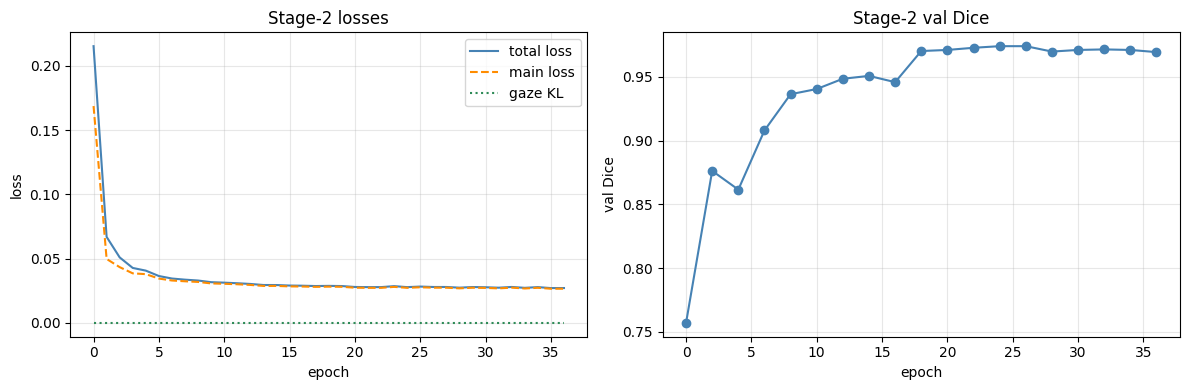

Saved results/stage1_curves.png


In [ ]:
if REAL_TRAIN_DONE and os.path.exists('results/stage1_history.json'):
    import matplotlib.pyplot as plt
    hist = pd.read_json('results/stage1_history.json')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(hist['epoch'], hist['loss'], label='total loss', color='steelblue')
    axes[0].plot(hist['epoch'], hist['main_loss'], label='main loss', color='darkorange', ls='--')
    axes[0].plot(hist['epoch'], hist['gaze_kl'], label='gaze KL', color='seagreen', ls=':')
    axes[0].set_xlabel('epoch'); axes[0].set_ylabel('loss'); axes[0].set_title('Stage-2 losses')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    if 'val_Dice' in hist.columns:
        v = hist.dropna(subset=['val_Dice'])
        axes[1].plot(v['epoch'], v['val_Dice'], marker='o', color='steelblue')
        axes[1].set_ylabel('val Dice'); axes[1].set_title('Stage-2 val Dice')
    else:
        axes[1].text(0.5, 0.5, 'no val_Dice recorded', ha='center', va='center')
    axes[1].set_xlabel('epoch'); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('results/stage1_curves.png', dpi=150)
    plt.show()
    print('Saved results/stage1_curves.png')
else:
    print('No training-curve plot — CPU dry run (no history to plot).')

## 11 — Final status banner

One unambiguous indicator of what actually happened in this run.

In [ ]:
from IPython.display import Markdown, display

if REAL_TRAIN_DONE:
    agg = (status.get('stage1_metrics') or {}).get('aggregate', {})
    dice_info = agg.get('Dice', {})
    banner = f"""
# REAL WORK DONE — GPU STRATIFIED 80/10/10 TRAINING COMPLETED

Ran **{NUM_FOLDS} folds** on GPU ({'smoke test' if SMOKE_TEST else 'full epochs'}).

| | |
|---|---|
| **Best fold** | **{status.get('best_fold')}** |
| **Best val Dice (single fold)** | **{status.get('best_val_dice', float('nan')):.4f}** |
| **Mean Dice ± std** | {dice_info.get('mean', float('nan')):.4f} ± {dice_info.get('std', float('nan')):.4f} |
| **Saved** | `checkpoints/stage1_best.pth`, `results/stage1_metrics.json` |
"""
    box = '#' * 64
    print(box)
    print('#  STRATIFIED 80/10/10 TRAINING COMPLETED')
    print('#  best val Dice = {:.4f}'.format(status.get('best_val_dice', float('nan'))))
    print(box)
else:
    banner = f"""
# TEST-ONLY RUN — NO REAL WORK DONE

Code was **validated on CPU** (fwd + gaze-KL bwd + eval OK) but **no real training**
was performed and no `stage1_*` checkpoints were written.

| | |
|---|---|
| **Mode** | CPU dry run |
| **Code check** | {'PASSED' if status['code_check_passed'] else 'FAILED'} |
| **Real training** | **NOT performed** |

Re-run on a **GPU Colab runtime** for real scratch results.
"""
    box = '!' * 64
    print(box)
    print('!!  TEST-ONLY RUN  -  NO SCRATCH TRAINING WAS PERFORMED  !!')
    print('!!  Code check:', 'PASSED' if status['code_check_passed'] else 'FAILED', '| mode:', status['mode'])
    print('!!  Re-run on a GPU runtime for real results.')
    print(box)

display(Markdown(banner))

################################################################
#  STRATIFIED 80/10/10 TRAINING COMPLETED
#  best val Dice = -1.0000
################################################################



# REAL WORK DONE — GPU STRATIFIED 80/10/10 TRAINING COMPLETED

Ran **1 folds** on GPU (full epochs).

| | |
|---|---|
| **Best fold** | **None** |
| **Best val Dice (single fold)** | **-1.0000** |
| **Mean Dice ± std** | 0.9711 ± 0.0000 |
| **Saved** | `checkpoints/stage1_best.pth`, `results/stage1_metrics.json` |


## 12 — Final evaluation: Tufts test (once) + OralXrays forgetting baseline

Evaluate the test set once per trained model. Loads best model and exports metrics + predictions for NB05-NB08.

In [18]:
# Load best weights and run held-out evaluations (OralXray primary; Tufts zero-shot secondary)
if REAL_TRAIN_DONE and os.path.exists('checkpoints/stage1_best.pth'):
    best_ckpt = torch.load('checkpoints/stage1_best.pth', map_location=device)
    model, _ = build_model_and_optimizer(CONFIG, device)
    model.load_state_dict(best_ckpt['model'])
    print(f'Loaded best Stage 1 weights (epoch {best_ckpt["epoch"]})')

    if 'loaders' not in locals() and 'loaders' not in globals():
        from dental_dataset import build_dataloaders, make_weighted_sampler
        from torch.utils.data import DataLoader
        loaders = build_dataloaders(CONFIG, PROJECT, image_root=LOCAL_DATA, smoke_test=SMOKE_TEST)

    oral_test_loader = loaders['oralxray_test']
    tufts_test_loader = loaders['tdd_test']

    oral_m, oral_targets, oral_preds, oral_probs, oral_ids = evaluate(
        model, oral_test_loader, collect_ids=True)
    tufts_m, tufts_targets, tufts_preds, tufts_probs, tufts_ids = evaluate(
        model, tufts_test_loader, collect_ids=True)

    from sklearn.metrics import confusion_matrix

    def _cm_block(name, m, targets, preds):
        cm = confusion_matrix(targets, preds)
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        print(f" {'='*55} {name} (threshold = {m.get('opt_threshold', 0.5):.3f}){'='*55}")
        print(f"  TN: {tn:5d}  |  FP: {fp:5d}")
        print(f"  FN: {fn:5d}  |  TP: {tp:5d}")
        print(f"  Precision: {tp/max(tp+fp,1):.4f} | Recall: {tp/max(tp+fn,1):.4f} | Specificity: {tn/max(tn+fp,1):.4f}{'='*55}")
        return {'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)}

    oral_cm = _cm_block('ORALXRAY TEST (Stage 1 in-distribution)', oral_m, oral_targets, oral_preds)
    tufts_cm = _cm_block('TUFTS TEST (Stage 1 zero-shot transfer)', tufts_m, tufts_targets, tufts_preds)

    metrics = {
        'phase': 'stage1_baseline_no_gaze',
        'training_dataset': 'oralxray',
        'evaluation_dataset_primary': 'oralxray_test',
        'evaluation_dataset_secondary': 'tufts_test_zero_shot',
        'best_epoch': int(best_ckpt['epoch']),
        'gaze_lambda_used': 0.0,
        'OralXray_test_Dice': float(oral_m['Dice']),
        'OralXray_test_F1': float(oral_m['F1']),
        'OralXray_test_Recall': float(oral_m['Recall']),
        'OralXray_test_AUROC': float(oral_m['AUROC']),
        'OralXray_CM': oral_cm,
        'Tufts_zero_shot_Dice': float(tufts_m['Dice']),
        'Tufts_zero_shot_F1': float(tufts_m['F1']),
        'Tufts_zero_shot_Recall': float(tufts_m['Recall']),
        'Tufts_zero_shot_AUROC': float(tufts_m['AUROC']),
        'Tufts_zero_shot_CM': tufts_cm,
    }

    if os.path.exists('results/stage1_metrics.json'):
        try:
            with open('results/stage1_metrics.json', 'r') as f:
                existing = json.load(f)
            existing.update(metrics)
            metrics = existing
        except Exception as e:
            print('Note: could not merge existing metrics:', e)

    with open('results/stage1_metrics.json', 'w') as f:
        json.dump(metrics, f, indent=2)

    pd.DataFrame({
        'id': oral_ids,
        'has_lesion_gt': oral_targets,
        'model_pred': oral_preds,
        'probs': oral_probs,
    }).to_csv('results/stage1_oralxray_per_image_predictions.csv', index=False)

    pd.DataFrame({
        'id': tufts_ids,
        'has_lesion_gt': tufts_targets,
        'model_pred': tufts_preds,
        'probs': tufts_probs,
    }).to_csv('results/stage1_tufts_zero_shot_predictions.csv', index=False)

    print('Saved results/stage1_metrics.json')
    print('Saved results/stage1_oralxray_per_image_predictions.csv')
    print('Saved results/stage1_tufts_zero_shot_predictions.csv')
    print(json.dumps(metrics, indent=2))
else:
    print('SKIPPING final test-set evaluation — no stage1_best.pth or training not complete.')

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 LoRA applied: 5,423,138 / 32,942,492 trainable (16.462%)
  encoder: 141,312  decoder: 5,083,169  cls_head: 198,657
Loaded best Stage 1 weights (epoch 20)
 ======================================================= ORALXRAY TEST (Stage 1 in-distribution) (threshold = 0.082)=======================================================
  TN:    21  |  FP:     3
  FN:    87  |  TP:  1158
  Precision: 0.9974 | Recall: 0.9301 | Specificity: 0.8750=======================================================
 ======================================================= TUFTS TEST (Stage 1 zero-shot transfer) (threshold = 0.235)=======================================================
  TN:    43  |  FP:    23
  FN:    18  |  TP:    16
  Precision: 0.4103 | Recall: 0.4706 | Specificity: 0.6515=======================================================
Saved results/stage1_metrics.json
Saved results/stage1_oralxray_per_image_predictions.csv
Saved results/stage1_tufts_zero_shot_predictions.csv
{
  "split": "OralXray 80/

=== CONFUSION MATRIX (threshold = 0.082) ===
TN:    21 | FP:     3
FN:    87 | TP:  1158
Precision: 0.9974 | Recall: 0.9301
Specificity: 0.8750



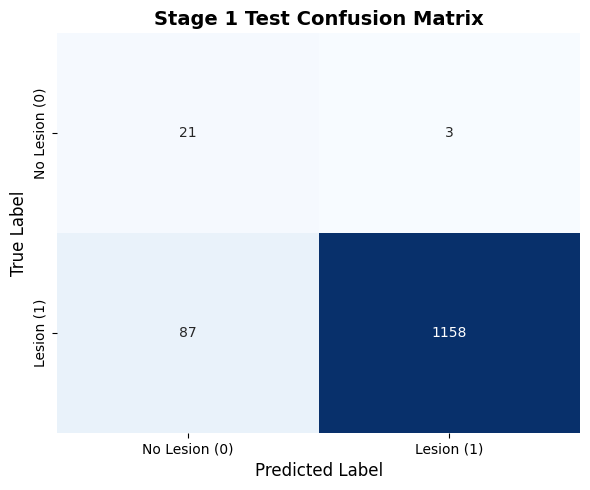

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Run evaluation on your test set
test_loader = loaders['oralxray_test']  # or loaders['test_tufts']
metrics, targets, preds, probs = evaluate(model, test_loader)

# 2. Compute confusion matrix
cm = confusion_matrix(targets, preds)
tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)

# 3. Display console metrics
print(f'=== CONFUSION MATRIX (threshold = {metrics.get("opt_threshold", 0.5):.3f}) ===')
print(f'TN: {tn:5d} | FP: {fp:5d}')
print(f'FN: {fn:5d} | TP: {tp:5d}')
print(
    f'Precision: {tp / max(tp + fp, 1):.4f} | Recall: {tp / max(tp + fn, 1):.4f}'
)
print(f'Specificity: {tn / max(tn + fp, 1):.4f}\n')

# 4. Plot visual heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=['No Lesion (0)', 'Lesion (1)'],
    yticklabels=['No Lesion (0)', 'Lesion (1)'],
)
plt.title('Stage 1 Test Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

⚡ Using device: cuda
✅ Successfully loaded 1871 total Dentex samples (batch size = 64).


Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


🎯 Loaded Stage 1 Model (from Epoch 20)

⏳ Running inference on Dentex dataset...
📊 Target Breakdown:
   -> Labeled Test Images: 1005 (Lesion: 936 | Healthy: 69)
   -> Unlabeled Images:    866 (Excluded from metric calculation)

   DENTEX LABELED TEST EVALUATION RESULTS (N = 1005)
  Dice Score (F1-Lesion): 0.4010  |  AUROC:     0.5180
  Optimal Threshold:      0.2673  |  Accuracy:  0.2925
------------------------------------------------------------
  CONFUSION MATRIX:
    True Negatives  (TN):    56  |  False Positives (FP):    13
    False Negatives (FN):   698  |  True Positives  (TP):   238
------------------------------------------------------------
  Precision (PPV):        0.9482  |  Recall:    0.2543
  Specificity (TNR):      0.8116

💾 Saved ALL 1,871 predictions (labeled + unlabeled) to: results/stage1_dentex_predictions.csv


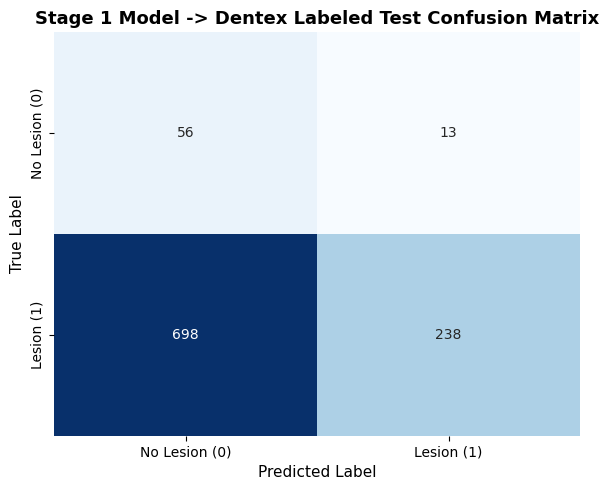

In [20]:
# ==============================================================================
#  FINAL DENTEX EVALUATION CELL (Fixes SwinGazeModel Init + Excludes -1)
# ==============================================================================
import json
import os
from glob import glob
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image

# 1. Setup Device & Configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'⚡ Using device: {device}')

if 'CONFIG' not in locals() and 'CONFIG' not in globals():
  with open('config.json', 'r') as f:
    CONFIG = json.load(f)

# Safe configuration retrieval
batch_size = CONFIG.get(
    'chosen_batch_size', CONFIG.get('effective_batch_size', 64)
)

# 2. Define Smart Dentex Dataset
DENTEX_FOLDER = '/content/dental_data/data/dentex/test_data'
SPLIT_CSV = 'splits/dentex_test_split.csv'


class ColabDentexDataset(Dataset):

  def __init__(self, csv_path, img_folder):
    self.df = (
        pd.read_csv(csv_path) if os.path.exists(csv_path) else pd.DataFrame()
    )
    self.img_folder = img_folder
    self.img_map = {}
    if os.path.exists(img_folder):
      for p in glob(os.path.join(img_folder, '**/*.*'), recursive=True):
        if p.lower().endswith(('.png', '.jpg', '.jpeg')):
          self.img_map[os.path.splitext(os.path.basename(p))[0]] = p

    # Standard ImageNet normalization matching DentalDataset class constants
    self.transform = transforms.Compose([
        transforms.Resize((224, 224), Image.Resampling.BILINEAR),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ])

  def __len__(self):
    return len(self.df)

  def __getitem__(self, idx):
    row = self.df.iloc[idx]
    img_id = str(row['id'])

    if img_id in self.img_map:
      img_path = self.img_map[img_id]
    else:
      rel_path = str(row['image_path'])
      img_path = (
          rel_path
          if os.path.isabs(rel_path)
          else os.path.join('/content/dental_data', rel_path)
      )

    try:
      img = Image.open(img_path).convert('RGB')
    except Exception:
      img = Image.new('RGB', (224, 224), color=0)

    img_tensor = self.transform(img)
    label = float(row['has_lesion_gt'])

    return {
        'image': img_tensor,
        'has_lesion_gt': label,
        'image_id': img_id,
        'image_path': img_path,
    }


dentex_ds = ColabDentexDataset(SPLIT_CSV, DENTEX_FOLDER)
dentex_loader = DataLoader(
    dentex_ds, batch_size=batch_size, shuffle=False, num_workers=2
)
print(
    f'✅ Successfully loaded {len(dentex_ds)} total Dentex samples (batch size'
    f' = {batch_size}).'
)

# 3. Load Pre-trained Stage 1 Model
best_ckpt_path = 'checkpoints/stage1_best.pth'
ckpt = torch.load(best_ckpt_path, map_location=device)

from core_modules import SwinGazeModel

# 🚨 FIXED LINE: Pass only CONFIG into SwinGazeModel
model = SwinGazeModel(CONFIG).to(device)
model.load_state_dict(ckpt['model'])
model.eval()
print(f'🎯 Loaded Stage 1 Model (from Epoch {ckpt.get("epoch", "Unknown")})')

# 4. Safe Inference Loop
print('\n⏳ Running inference on Dentex dataset...')
all_targets, all_probs, all_ids = [], [], []

with torch.no_grad():
  for batch in dentex_loader:
    imgs = batch['image'].to(device)
    labels = batch['has_lesion_gt'].numpy()
    ids = batch['image_id']

    out = model(imgs)
    logits = out[0] if isinstance(out, (tuple, list)) else out
    probs = torch.sigmoid(logits).squeeze(-1).cpu().numpy()

    all_targets.extend(labels)
    all_probs.extend(probs)
    all_ids.extend(ids)

all_targets = np.array(all_targets)
all_probs = np.array(all_probs)

# 🚨 FILTER OUT -1 (UNLABELED IMAGES) FOR BINARY METRIC CALCULATION!
valid_mask = all_targets != -1
val_targets = all_targets[valid_mask].astype(int)
val_probs = all_probs[valid_mask]
unlabeled_count = np.sum(~valid_mask)

print(f'📊 Target Breakdown:')
print(
    f'   -> Labeled Test Images: {len(val_targets)} (Lesion:'
    f' {np.sum(val_targets == 1)} | Healthy: {np.sum(val_targets == 0)})'
)
print(
    f'   -> Unlabeled Images:    {unlabeled_count} (Excluded from metric'
    ' calculation)'
)

# 5. Calibrate Threshold on Labeled Subset & Compute Metrics
from core_modules import calibrate_decision_threshold

opt_thresh = calibrate_decision_threshold(val_targets, val_probs)
val_preds = (val_probs > opt_thresh).astype(int)

auroc = (
    roc_auc_score(val_targets, val_probs)
    if len(np.unique(val_targets)) > 1
    else 0.0
)
f1 = f1_score(val_targets, val_preds, zero_division=0)
recall = recall_score(val_targets, val_preds, zero_division=0)
precision = precision_score(val_targets, val_preds, zero_division=0)

cm = confusion_matrix(val_targets, val_preds)
tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
dice = (2 * tp) / max(2 * tp + fp + fn, 1)
specificity = tn / max(tn + fp, 1)

# 6. Print Formatted Results
print(f"\n{'='*60}")
print(f'   DENTEX LABELED TEST EVALUATION RESULTS (N = {len(val_targets)})')
print(f"{'='*60}")
print(f'  Dice Score (F1-Lesion): {dice:.4f}  |  AUROC:     {auroc:.4f}')
print(
    f'  Optimal Threshold:      {opt_thresh:.4f}  |  Accuracy:'
    f'  {(tp+tn)/len(val_targets):.4f}'
)
print(f"{'-'*60}")
print(f'  CONFUSION MATRIX:')
print(f'    True Negatives  (TN): {tn:5d}  |  False Positives (FP): {fp:5d}')
print(f'    False Negatives (FN): {fn:5d}  |  True Positives  (TP): {tp:5d}')
print(f"{'-'*60}")
print(f'  Precision (PPV):        {precision:.4f}  |  Recall:    {recall:.4f}')
print(f'  Specificity (TNR):      {specificity:.4f}')
print(f"{'='*60}\n")

# 7. Save ALL Predictions (Labeled + Unlabeled) to CSV
out_df = pd.DataFrame({
    'id': all_ids,
    'has_lesion_gt': all_targets,
    'prob': all_probs,
    'pred': (all_probs > opt_thresh).astype(int),
})
out_csv = 'results/stage1_dentex_predictions.csv'
os.makedirs('results', exist_ok=True)
out_df.to_csv(out_csv, index=False)
print(f'💾 Saved ALL 1,871 predictions (labeled + unlabeled) to: {out_csv}')

# 8. Plot Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=['No Lesion (0)', 'Lesion (1)'],
    yticklabels=['No Lesion (0)', 'Lesion (1)'],
)
plt.title(
    'Stage 1 Model -> Dentex Labeled Test Confusion Matrix',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Predicted Label', fontsize=11)
plt.ylabel('True Label', fontsize=11)
plt.tight_layout()
plt.show()

Files found in /content/dental_data/data/dentex/test_data: 500
  Example: /content/dental_data/data/dentex/test_data/disease/label/test_142.json

CSV expects paths like:
   data/dentex/quadrant_enumeration_disease/xrays/val_15.png

Spot check: loading 5 labeled images...
  ✅ OK (max pixel = 255): val_15.png
  ✅ OK (max pixel = 255): val_38.png
  ✅ OK (max pixel = 255): val_33.png
  ✅ OK (max pixel = 255): val_30.png
  ✅ OK (max pixel = 255): val_5.png

Summary → OK: 5 | Black: 0 | Missing: 0


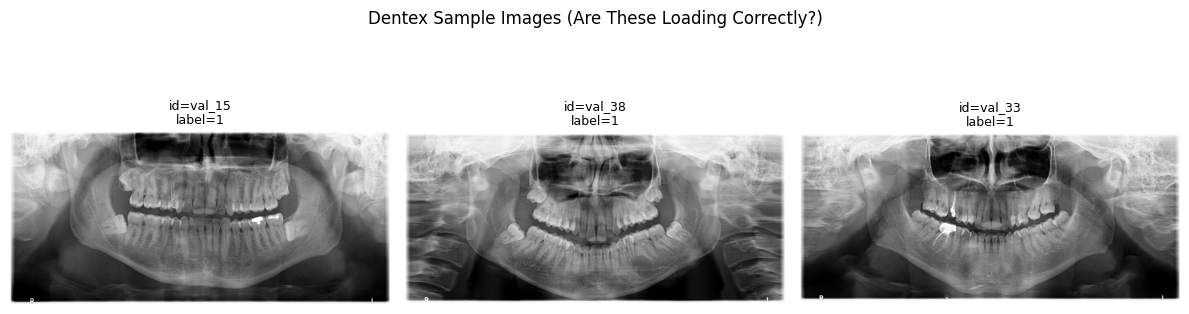

In [21]:
# ============================================================
#  VERIFY DENTEX IMAGE LOADING — RUN THIS BEFORE EVALUATION
# ============================================================
import os, pandas as pd
from glob import glob
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

DENTEX_FOLDER = '/content/dental_data/data/dentex/test_data'
SPLIT_CSV     = 'splits/dentex_test_split.csv'

df = pd.read_csv(SPLIT_CSV)
labeled = df[df['has_lesion_gt'] != -1]

# 1. What files exist in the folder the user specified?
found = glob(os.path.join(DENTEX_FOLDER, '**/*.*'), recursive=True)
print(f'Files found in {DENTEX_FOLDER}: {len(found)}')
if found:
    print('  Example:', found[0])

# 2. What paths does the CSV expect?
print(f'\nCSV expects paths like:')
print('  ', labeled['image_path'].iloc[0])

# 3. Manually try loading 5 images and check if they are black
print('\nSpot check: loading 5 labeled images...')
n_ok, n_black, n_missing = 0, 0, 0
for _, row in labeled.head(5).iterrows():
    rel = row['image_path']
    full = os.path.join('/content/dental_data', rel)
    if not os.path.exists(full):
        print(f'  ❌ MISSING: {full}')
        n_missing += 1
    else:
        arr = np.array(Image.open(full).convert('RGB'))
        if arr.max() == 0:
            print(f'  ⚠️  BLACK IMAGE: {full}')
            n_black += 1
        else:
            print(f'  ✅ OK (max pixel = {arr.max()}): {os.path.basename(full)}')
            n_ok += 1

print(f'\nSummary → OK: {n_ok} | Black: {n_black} | Missing: {n_missing}')

# 4. Show 3 sample images visually
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for i, (_, row) in enumerate(labeled.head(3).iterrows()):
    full = os.path.join('/content/dental_data', row['image_path'])
    try:
        img = Image.open(full).convert('RGB')
    except Exception:
        img = Image.new('RGB', (224, 224), color=0)
    axs[i].imshow(img)
    axs[i].set_title(
        f"id={row['id']}\nlabel={row['has_lesion_gt']}", fontsize=9
    )
    axs[i].axis('off')
plt.suptitle('Dentex Sample Images (Are These Loading Correctly?)', fontsize=12)
plt.tight_layout()
plt.show()